# HDT 8: Redes Neuronales

**Ciencia de Datos, Sección A** · Asignada: jueves 15 de octubre · **Entrega: martes 27 de octubre, 23:59**

**Nombre:** _Victor Saravia_
**Carné no.:** _20240060_

Completar las celdas marcadas con `# ¿Qué va aquí?`. Cada ejercicio incluye una verificación comentada: descomentar para comprobar el resultado. Antes de entregar: **Kernel → Restart & Run All** (un notebook que no corre de arriba a abajo pierde 0.5 pts).

La entrega es el martes del repaso (el 20 es feriado): no la dejen para el final, el Parcial II es el jueves 29.

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).

## Setup

Dependencias: `pip install numpy pandas matplotlib scikit-learn`. Todo es determinista (semillas fijas y splits fijos): las verificaciones son exactas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

def frontera(modelo, X, y, ax, titulo):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 150),
                         np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 150))
    Z = modelo.predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=[AZUL, ROJO], alpha=0.2)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(y == 1, ROJO, AZUL), s=12)
    ax.set_title(titulo, fontsize=10)

## Los datos

Dos problemas donde la forma importa:

**La alarma** (parte A): un sensor dispara la alarma cuando **exactamente una** de dos señales está encendida (la diagonal de la sesión 22, con otros 240 puntos). **Los anillos** (parte B): un punto adentro de un anillo, como el ejercicio 2 de clase, con otros números.

In [2]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(15)
esquinas = rng.integers(0, 2, size=(240, 2))
X_alarma = esquinas + rng.normal(0, 0.15, (240, 2))
y_alarma = (esquinas[:, 0] != esquinas[:, 1]).astype(int)

X_ani, y_ani = make_circles(n_samples=500, noise=0.12, factor=0.45, random_state=8)
Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_ani, y_ani, test_size=0.3, random_state=42)

print("alarma:", len(X_alarma), "puntos | anillos:", len(X_ani), "puntos")

alarma: 240 puntos | anillos: 500 puntos


## Parte A · La recta falla, la red a mano no (0.7 pt)

### Ejercicio 1 (0.20): la recta contra la diagonal

Entrenar una `LogisticRegression` sobre la alarma y reportar sus aciertos. Graficar los puntos (ROJO = alarma, AZUL = no) con `eje_limpio`. En un comentario: ¿por qué este número y no algo mejor?

aciertos de la recta: 0.54


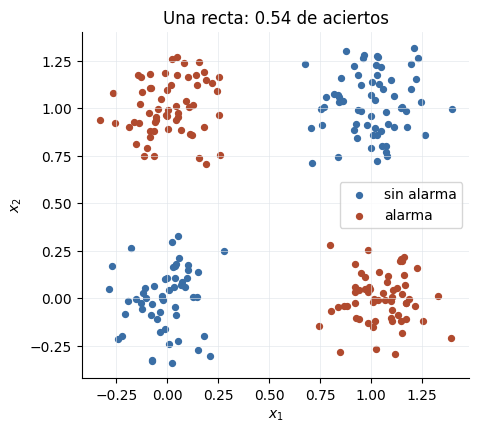

In [3]:
from sklearn.linear_model import LogisticRegression

recta = LogisticRegression().fit(X_alarma, y_alarma)
aciertos_recta = recta.score(X_alarma, y_alarma)
print("aciertos de la recta:", round(aciertos_recta, 2))

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(X_alarma[y_alarma == 0, 0], X_alarma[y_alarma == 0, 1], c=AZUL, s=18, label="sin alarma")
ax.scatter(X_alarma[y_alarma == 1, 0], X_alarma[y_alarma == 1, 1], c=ROJO, s=18, label="alarma")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title=f"Una recta: {aciertos_recta:.2f} de aciertos")
ax.legend()
eje_limpio(ax)
plt.show()

# Respuesta: los casos con alarma están en esquinas opuestas (XOR). Una sola recta no puede aislar las dos esquinas rojas de las dos azules, por eso acierta 0.54.

# Verificación:
assert round(aciertos_recta, 2) == 0.54

### Ejercicio 2 (0.30): la red a mano, verificada

Completar `red_a_mano` con la receta de clase: neurona 1 con pesos $(2, 2)$ y sesgo $-1$; neurona 2 con pesos $(2, 2)$ y sesgo $-3$; ambas con ReLU; salida $= h_1 - 3 h_2$. Armar la tabla de las cuatro esquinas e imprimirla.

In [4]:
def relu(z):
    return np.maximum(0, z)

def red_a_mano(x1, x2):
    suma1 = 2 * x1 + 2 * x2 - 1
    h1 = relu(suma1)
    suma2 = 2 * x1 + 2 * x2 - 3
    h2 = relu(suma2)
    salida = h1 - 3 * h2
    return salida

filas = []
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    h1 = relu(2 * x1 + 2 * x2 - 1)
    h2 = relu(2 * x1 + 2 * x2 - 3)
    filas.append({"x1": x1, "x2": x2, "h1": h1, "h2": h2,
                  "salida": red_a_mano(x1, x2)})
print(pd.DataFrame(filas).to_string(index=False))

# h1 se activa si hay al menos un 1, h2 resta la activación del caso (1, 1).
assert red_a_mano(0, 1) == 1 and red_a_mano(1, 0) == 1
assert red_a_mano(0, 0) == 0 and red_a_mano(1, 1) == 0

 x1  x2  h1  h2  salida
  0   0   0   0       0
  0   1   1   0       1
  1   0   1   0       1
  1   1   3   1       0


### Ejercicio 3 (0.20): la misma red sobre los 240 puntos

Aplicar `red_a_mano` a todos los puntos de la alarma (decidir sí cuando la salida pasa de 0.5) y reportar los aciertos. Comparar contra la recta del ejercicio 1 en un comentario.

In [5]:
salidas = np.array([red_a_mano(x1, x2) for x1, x2 in X_alarma])
pred_mano = (salidas > 0.5).astype(int)
aciertos_mano = (pred_mano == y_alarma).mean()
print("aciertos de la red a mano:", round(aciertos_mano, 2))
print("aciertos de la recta:", round(aciertos_recta, 2))

# Respuesta: la red forma una franja entre dos umbrales y reconoce ambas esquinas positivas. Mejora de 0.54 a 0.89; el ruido mueve algunos puntos fuera de la franja.
assert round(aciertos_mano, 2) == 0.89

aciertos de la red a mano: 0.89
aciertos de la recta: 0.54


## Parte B · La red que aprende (0.7 pt)

Los anillos: un círculo adentro de otro. La pregunta de la clase: ¿cuántos quiebres pide esta frontera?

### Ejercicio 4 (0.25): ¿cuántas neuronas pide un anillo?

Para [1, 2, 4, 8, 16, 64] neuronas de en medio: entrenar `MLPClassifier` (`activation="relu"`, `max_iter=3000`, `random_state=0`) sobre el train de los anillos y guardar train y test en una tabla. ¿Dónde deja de mejorar?

In [6]:
from sklearn.neural_network import MLPClassifier
import warnings
from sklearn.exceptions import ConvergenceWarning

filas = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    warnings.simplefilter("ignore", ConvergenceWarning)
    for h in [1, 2, 4, 8, 16, 64]:
        modelo = MLPClassifier(hidden_layer_sizes=(h,), activation="relu",
                               max_iter=3000, random_state=0).fit(Xa_train, ya_train)
        filas.append({"neuronas": h,
                      "train": round(modelo.score(Xa_train, ya_train), 2),
                      "test": round(modelo.score(Xa_test, ya_test), 2)})
tabla_h = pd.DataFrame(filas)
print(tabla_h.to_string(index=False))

# En test, la mejora llega hasta 8 neuronas (0.99); 16 y 64 siguen en 0.99.
assert tabla_h["test"].tolist() == [0.45, 0.58, 0.95, 0.99, 0.99, 0.99]

 neuronas  train  test
        1   0.52  0.45
        2   0.58  0.58
        4   0.98  0.95
        8   1.00  0.99
       16   0.99  0.99
       64   0.99  0.99


### Ejercicio 5 (0.25): las fronteras, dibujadas

Tres paneles con `frontera(...)`: redes de 1, 4 y 8 neuronas sobre el test de los anillos, con los aciertos de test en cada título.

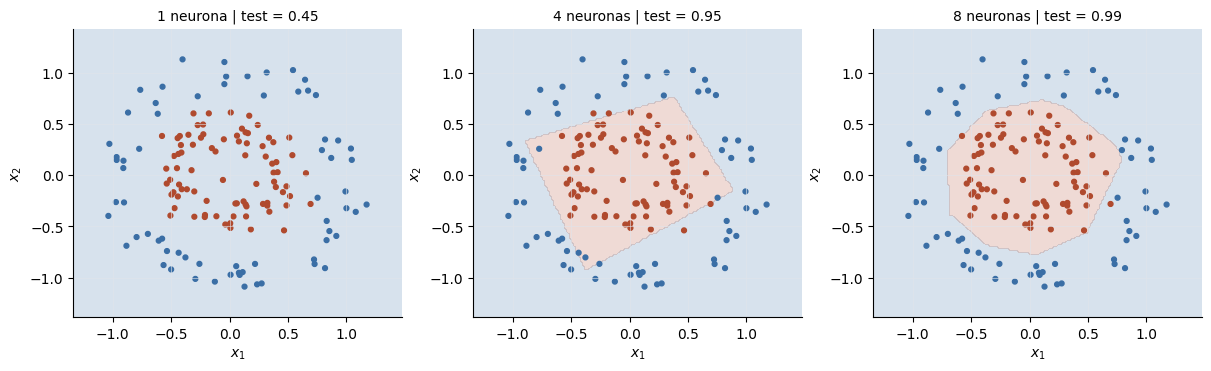

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    warnings.simplefilter("ignore", ConvergenceWarning)
    for ax, h in zip(axes, [1, 4, 8]):
        modelo = MLPClassifier(hidden_layer_sizes=(h,), activation="relu",
                               max_iter=3000, random_state=0).fit(Xa_train, ya_train)
        aciertos = modelo.score(Xa_test, ya_test)
        frontera(modelo, Xa_test, ya_test, ax, f"{h} {'neurona' if h == 1 else 'neuronas'} | test = {aciertos:.2f}")
        ax.set(xlabel="$x_1$", ylabel="$x_2$")
        eje_limpio(ax)
plt.show()

# Una neurona deja una frontera insuficiente. 4 rodean casi todo el centro, con 8 la frontera se adapta mejor al anillo.
assert len(axes) == 3

### Ejercicio 6 (0.20): el tamaño del paso, otra vez

Entrenar la red de 8 neuronas con `solver="sgd"` y `learning_rate_init` en [0.001, 0.1, 8.0] (`max_iter=400`), graficando la curva de error (`loss_curve_`) de cada una. Guardar los aciertos de test en `tests_paso`. En un comentario: ¿qué historia cuenta cada curva?

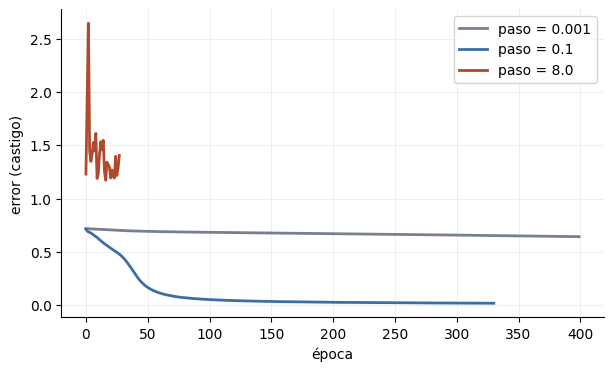

 paso  épocas  error final  test
0.001     400        0.643  0.67
0.100     331        0.019  0.97
8.000      28        1.404  0.55


In [8]:
import warnings
from sklearn.exceptions import ConvergenceWarning

tests_paso = {}
filas_paso = []
fig, ax = plt.subplots(figsize=(7, 4))
for lr, color in zip([0.001, 0.1, 8.0], [GRIS, AZUL, ROJO]):
    modelo = MLPClassifier(hidden_layer_sizes=(8,), activation="relu", solver="sgd",
                           learning_rate_init=lr, max_iter=400, random_state=0)
    # El paso 8.0 produce avisos de desbordamiento; la tabla conserva su resultado.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        warnings.simplefilter("ignore", ConvergenceWarning)
        modelo.fit(Xa_train, ya_train)
        tests_paso[lr] = modelo.score(Xa_test, ya_test)
    ax.plot(modelo.loss_curve_, color=color, lw=2, label=f"paso = {lr}")
    filas_paso.append({"paso": lr, "épocas": len(modelo.loss_curve_),
                       "error final": round(modelo.loss_curve_[-1], 3),
                       "test": round(tests_paso[lr], 2)})
ax.set_xlabel("época"); ax.set_ylabel("error (castigo)")
ax.legend(); eje_limpio(ax)
plt.show()
tabla_paso = pd.DataFrame(filas_paso)
print(tabla_paso.to_string(index=False))

# Respuesta: 0.001 aprende muy despacio, 0.1 reduce el error y logra 0.97 en test, 8.0 da saltos inestables y termina pronto con mucho error y solo 0.55 en test.
assert round(tests_paso[0.1], 2) == 0.97
assert tests_paso[8.0] < 0.6

## Parte C · La culpa, a mano (0.4 pt)

Backpropagation en miniatura: UNA neurona, UN peso, y la pregunta de la sesión: ¿cuánto ayudó este peso al error? Sin derivadas: se le sube un poquito y se mira qué pasa.

### Ejercicio 7 (0.40): mover un peso en contra de su culpa

Una neurona sola decide si un cliente con `x` meses de atraso cae en mora: $p = \text{sigmoide}(w \cdot x - 2.5)$. Datos: x = [1, 2, 3, 4], y = [0, 0, 1, 1]. La función `castigo(w)` ya está dada.

Completar el loop de 25 pasos: (a) medir la **culpa** del peso: subirlo 0.01 y ver cuánto cambia el castigo, dividido entre 0.01; (b) mover `w` en contra: `w = w - 0.5 * culpa`. Imprimir el castigo inicial, el final y el corte aprendido ($x = 2.5 / w$).

In [9]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

x_mora = np.array([1.0, 2.0, 3.0, 4.0])
y_mora = np.array([0, 0, 1, 1])

def castigo(w):
    p = sigmoide(w * x_mora - 2.5).clip(1e-9, 1 - 1e-9)
    return float(-np.mean(y_mora * np.log(p) + (1 - y_mora) * np.log(1 - p)))

w = 0.0
print("castigo inicial:", round(castigo(w), 3))
for paso in range(25):
    culpa = (castigo(w + 0.01) - castigo(w)) / 0.01
    w = w - 0.5 * culpa

print("w final:", round(w, 3), "| castigo final:", round(castigo(w), 3))
print("el corte aprendido está en x =", round(2.5 / w, 2))

# La culpa aproxima la pendiente del castigo: si es positiva, bajar w lo reduce, si es negativa, subir w lo reduce. El corte es donde la probabilidad llega a 0.5.
assert round(w, 3) == 1.183
assert round(castigo(w), 3) == 0.317

castigo inicial: 1.329
w final: 1.183 | castigo final: 0.317
el corte aprendido está en x = 2.11


## Parte D · Criterio (0.2 pt)

### Ejercicio 8 (0.20)

Dos preguntas, 2-3 líneas cada una, **citando los números obtenidos**:

**(a)** Para los anillos, ¿cuántas neuronas usarían en producción y por qué? Citar la tabla del ejercicio 4 (considerar qué aporta 64 contra 8).

**(b)** Un compañero defiende el paso 8.0 porque "terminó en 28 épocas, fue el más rápido". Con los números del ejercicio 6, explicar el error de ese argumento.

**Respuesta (a):** Usaría 8 neuronas, pues logra 0.99 en test y 1 en train. Con 64, el test sigue en 0.99 y train baja a 0.99, las 56 neuronas extra no aportan precisión en estos datos y aumentan el costo del modelo.

**Respuesta (b):** El paso 8.0 acabó en 28 épocas, pero obtuvo 0.55 en test y error final 1.404. El paso 0.1 tardó 331 épocas, pero logró 0.97 en test y error 0.019. Por ende, menos épocas no significa un modelo mejor si el entrenamiento es inestable.

## Bitácora de AI (opcional, no penaliza)

Usé AI para comprender por qué XOR no se separa con una recta, como las ReLU forman la franja de decisión y como interpretar las curvas de error. También me ayudé para verificar los ejercicios, pero con el jupyter y presentación de clase me fui guiando y eso me facilitó completarlo.